In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

np.random.seed(2026)



In [16]:
# Global styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [17]:
n_samples = 80
rpm = np.random.uniform(1000, 6000, size=n_samples) # RPM = revolutions per minute
efficiency = 8 + 0.008 * rpm - 0.0000012 * (rpm ** 2) + np.random.normal(0, 1.2, size=n_samples)

df_engine = pd.DataFrame({
    "rpm": rpm.round(),
    "fuel_efficiency_kml": efficiency.round(2)
}).sort_values(by="rpm").reset_index(drop=True) # drop=True tells Pandas: "Discard the old index completely instead of keeping it as a new column."

print(df_engine.head())

      rpm  fuel_efficiency_kml
0  1012.0                13.46
1  1115.0                15.35
2  1153.0                15.49
3  1234.0                18.93
4  1241.0                16.30


In [27]:
X_sample = df_engine[["rpm"]].head(3)
poly_transformer = PolynomialFeatures(degree=2, include_bias=True)
X_poly_sample = poly_transformer.fit_transform(X_sample)

print("Original Fetures (RPM)\n",X_sample.values)
print(f"Polynomial Features ({', '.join(poly_transformer.get_feature_names_out())})\n",X_poly_sample)


Original Fetures (RPM)
 [[1012.]
 [1115.]
 [1153.]]
Polynomial Features (1, rpm, rpm^2)
 [[1.000000e+00 1.012000e+03 1.024144e+06]
 [1.000000e+00 1.115000e+03 1.243225e+06]
 [1.000000e+00 1.153000e+03 1.329409e+06]]


In [ ]:
X = df_engine[["rpm"]] # predictor variable (RPM)
y = df_engine["fuel_efficiency_kml"] # response variable (fuel efficiency in km/l)

X_plot = pd.DataFrame({
    "rpm": np.linspace(1000,6000, 300)
})


           rpm
0  1000.000000
1  1016.722408
2  1033.444816
3  1050.167224
4  1066.889632


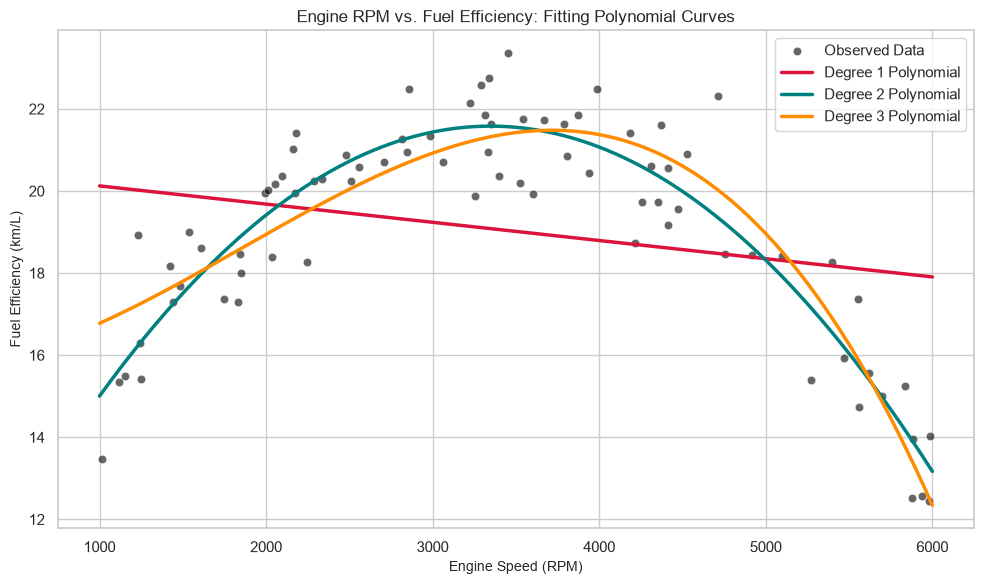

In [32]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_engine, x="rpm", y="fuel_efficiency_kml", color="black", alpha=0.6, label="Observed Data")

degrees = [1, 2, 3]
colors = ["crimson", "teal", "darkorange"]
for degree, color in zip(degrees, colors):
    model_pipe = make_pipeline(PolynomialFeatures(degree=degree), LinearRegression())
    model_pipe.fit(X, y)
    y_plot = model_pipe.predict(X_plot)
    plt.plot(X_plot["rpm"], y_plot, color=color, linewidth=2.5, label=f"Degree {degree} Polynomial")


plt.title("Engine RPM vs. Fuel Efficiency: Fitting Polynomial Curves", fontsize=12)
plt.xlabel("Engine Speed (RPM)", fontsize=10)
plt.ylabel("Fuel Efficiency (km/L)", fontsize=10)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()